<a href="https://colab.research.google.com/github/BenMedjeghaiaMahdi/ML-Model-for-Student-Performance-Predictions/blob/main/task0%2B1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OrdinalEncoder, OneHotEncoder
RANDOM_STATE=42

In [ ]:
studenttrain = pd.read_csv("studentdata.csv")
studenttrain.head()

,StudentID,Name,Gender,AttendanceRate,StudyHoursPerWeek,PreviousGrade,ExtracurricularActivities,ParentalSupport,FinalGrade,Study Hours,Attendance (%),Online Classes Taken
0,1.0,John,Male,85.0,15.0,78.0,1.0,High,80.0,4.8,59.0,False
1,2.0,Sarah,Female,90.0,20.0,85.0,2.0,Medium,87.0,2.2,70.0,True
2,3.0,Alex,Male,78.0,10.0,65.0,0.0,Low,68.0,4.6,92.0,False
3,4.0,Michael,Male,92.0,25.0,90.0,3.0,High,92.0,2.9,96.0,False
4,5.0,Emma,Female,NaN,18.0,82.0,2.0,Medium,85.0,4.1,97.0,True


In [ ]:
studenttrain.corr(numeric_only=True)["FinalGrade"]

,FinalGrade
StudentID,0.078321
AttendanceRate,-0.014768
StudyHoursPerWeek,0.036394
PreviousGrade,0.003982
ExtracurricularActivities,-0.026133
FinalGrade,1.000000
Study Hours,0.031023
Attendance (%),0.040807


In [ ]:
studenttrain.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   StudentID                  960 non-null    float64
 1   Name                       966 non-null    object 
 2   Gender                     952 non-null    object 
 3   AttendanceRate             960 non-null    float64
 4   StudyHoursPerWeek          950 non-null    float64
 5   PreviousGrade              967 non-null    float64
 6   ExtracurricularActivities  957 non-null    float64
 7   ParentalSupport            978 non-null    object 
 8   FinalGrade                 960 non-null    float64
 9   Study Hours                976 non-null    float64
 10  Attendance (%)             959 non-null    float64
 11  Online Classes Taken       975 non-null    object 
dtypes: float64(8), object(4)
memory usage: 93.9+ KB


In [ ]:
studenttrain.shape

(1000, 12)

In [ ]:
studenttrain.describe().T

,count,mean,std,min,25%,50%,75%,max
StudentID,960.0,5416.019792,2653.748319,1.0,3113.5,5396.5,7754.75,9998.0
AttendanceRate,960.0,85.510417,7.332125,70.0,82.0,88.0,91.00,95.0
StudyHoursPerWeek,950.0,17.630526,6.272132,8.0,12.0,18.0,22.00,30.0
PreviousGrade,967.0,77.598759,10.006640,60.0,70.0,78.0,86.00,90.0
ExtracurricularActivities,957.0,1.520376,1.046439,0.0,1.0,1.0,2.00,3.0
FinalGrade,960.0,80.030208,9.493652,62.0,72.0,80.0,88.00,92.0
Study Hours,976.0,2.406967,1.620267,-5.0,1.2,2.5,3.70,5.0
Attendance (%),959.0,77.248175,19.298148,50.0,63.0,76.0,89.00,200.0


In [ ]:

studenttrain.isnull().sum()

,0
StudentID,40
Name,34
Gender,48
AttendanceRate,40
StudyHoursPerWeek,50
PreviousGrade,33
ExtracurricularActivities,43
ParentalSupport,22
FinalGrade,40
Study Hours,24


In [ ]:
missing_rows = studenttrain[studenttrain.isnull().any(axis=1)]
print("nb lines with missing values", len(missing_rows))
display(missing_rows.head())

nb lines with missing values 355


,StudentID,Name,Gender,AttendanceRate,StudyHoursPerWeek,PreviousGrade,ExtracurricularActivities,ParentalSupport,FinalGrade,Study Hours,Attendance (%),Online Classes Taken
4,5.0,Emma,Female,NaN,18.0,82.0,2.0,Medium,85.0,4.1,97.0,True
5,6.0,Olivia,Female,95.0,30.0,88.0,1.0,High,NaN,2.8,97.0,False
7,8.0,Sophia,Female,NaN,17.0,77.0,1.0,Medium,78.0,1.0,70.0,True
10,2824.0,Shannon Harrison,Male,88.0,25.0,90.0,0.0,NaN,87.0,3.4,84.0,True
11,7912.0,Peter Davila,Male,85.0,20.0,NaN,3.0,Low,88.0,0.1,62.0,False


In [ ]:
missing_study_hours = studenttrain[studenttrain['Study Hours'].isnull()]
print("missing lines'Study Hours':")
display(missing_study_hours)


missing_study_hours_week = studenttrain[studenttrain['StudyHoursPerWeek'].isnull()]
print("\n mmising line 'StudyHoursPerWeek':")
display(missing_study_hours_week)

missing lines'Study Hours':


,StudentID,Name,Gender,AttendanceRate,StudyHoursPerWeek,PreviousGrade,ExtracurricularActivities,ParentalSupport,FinalGrade,Study Hours,Attendance (%),Online Classes Taken
94,9998.0,Jeffrey Howard,Male,88.0,17.0,77.0,2.0,High,88.0,NaN,95.0,True
177,5089.0,Trevor Freeman,Male,85.0,NaN,77.0,2.0,Medium,72.0,NaN,99.0,False
197,3440.0,Brandon Williamson,Male,95.0,NaN,88.0,0.0,Medium,NaN,NaN,69.0,False
202,8837.0,Aimee Rogers,Female,95.0,10.0,77.0,2.0,Medium,72.0,NaN,99.0,False
204,9011.0,Michael Evans,Female,85.0,30.0,70.0,2.0,Medium,87.0,NaN,NaN,False
256,5040.0,Joseph Holt,Female,91.0,22.0,90.0,1.0,High,68.0,NaN,75.0,False
274,3733.0,Barry Parker,Female,NaN,10.0,65.0,1.0,Medium,88.0,NaN,72.0,True
280,3719.0,Benjamin White,Male,92.0,25.0,78.0,3.0,Medium,72.0,NaN,84.0,True
301,2956.0,Jason Horne DDS,Male,78.0,15.0,65.0,1.0,Medium,72.0,NaN,96.0,False
356,NaN,Dr. Richard Wallace,Male,92.0,30.0,77.0,3.0,Medium,68.0,NaN,80.0,False



 mmising line 'StudyHoursPerWeek':


,StudentID,Name,Gender,AttendanceRate,StudyHoursPerWeek,PreviousGrade,ExtracurricularActivities,ParentalSupport,FinalGrade,Study Hours,Attendance (%),Online Classes Taken
26,3705.0,Jeremy Hall,Female,NaN,NaN,60.0,3.0,Low,92.0,3.6,75.0,False
52,5930.0,Maria Cross,Female,82.0,NaN,82.0,NaN,High,62.0,3.9,88.0,False
95,6091.0,Morgan Bell,Male,82.0,NaN,85.0,NaN,High,78.0,4.7,91.0,True
101,9617.0,Emily Torres,NaN,85.0,NaN,60.0,0.0,High,78.0,3.9,66.0,False
121,9850.0,Christopher Baxter,Female,78.0,NaN,78.0,0.0,High,90.0,3.9,65.0,False
129,6400.0,Shari Harrell,Male,70.0,NaN,60.0,1.0,Medium,88.0,1.6,56.0,True
131,8030.0,David Hoffman,Male,91.0,NaN,78.0,0.0,Medium,85.0,4.6,72.0,True
162,2821.0,Leslie King,Female,92.0,NaN,85.0,1.0,High,NaN,3.2,89.0,False
177,5089.0,Trevor Freeman,Male,85.0,NaN,77.0,2.0,Medium,72.0,NaN,99.0,False
197,3440.0,Brandon Williamson,Male,95.0,NaN,88.0,0.0,Medium,NaN,NaN,69.0,False


In [ ]:
print("صفوف مكررة :", studenttrain.duplicated().sum())
print("StudentID    :", studenttrain['StudentID'].dropna().duplicated().sum())
display(studenttrain[studenttrain['StudentID'].duplicated(keep=False) & studenttrain['StudentID'].notna()]
        .sort_values('StudentID').head(6))

صفوف مكررة : 0
StudentID    : 44


,StudentID,Name,Gender,AttendanceRate,StudyHoursPerWeek,PreviousGrade,ExtracurricularActivities,ParentalSupport,FinalGrade,Study Hours,Attendance (%),Online Classes Taken
359,1138.0,Andrea Newman,NaN,88.0,22.0,82.0,2.0,Medium,62.0,4.3,79.0,False
983,1138.0,Holly Spencer,Female,88.0,8.0,70.0,3.0,Medium,62.0,3.6,58.0,True
290,1152.0,NaN,Male,NaN,20.0,60.0,0.0,Medium,87.0,1.1,55.0,True
38,1152.0,Jerry Browning,Female,91.0,22.0,85.0,2.0,Low,92.0,2.5,58.0,False
867,1324.0,Teresa Rodriguez,Female,70.0,20.0,82.0,3.0,Low,68.0,2.8,61.0,False
470,1324.0,Anne Martin,Female,90.0,30.0,86.0,NaN,Low,88.0,3.2,84.0,True


In [ ]:
pairs = studenttrain[['AttendanceRate', 'Attendance (%)', 'StudyHoursPerWeek', 'Study Hours']]
display(pairs.describe().loc[['min', 'max', 'mean']])
display(pairs.corr().round(2))

,AttendanceRate,Attendance (%),StudyHoursPerWeek,Study Hours
min,70.000000,50.000000,8.000000,-5.000000
max,95.000000,200.000000,30.000000,5.000000
mean,85.510417,77.248175,17.630526,2.406967


,AttendanceRate,Attendance (%),StudyHoursPerWeek,Study Hours
AttendanceRate,1.00,0.01,0.02,-0.02
Attendance (%),0.01,1.00,0.06,-0.32
StudyHoursPerWeek,0.02,0.06,1.00,-0.02
Study Hours,-0.02,-0.32,-0.02,1.00


In [ ]:
# Remove rows without the target: they cannot be used for supervised regression.
studenttrain = studenttrain.dropna(subset=['FinalGrade']).copy()

# Split the remaining data into training (70%), validation (15%), and test (15%).
train_data, temp_data = train_test_split(
    studenttrain, test_size=0.30, random_state=RANDOM_STATE
)
validation_data, test_data = train_test_split(
    temp_data, test_size=0.50, random_state=RANDOM_STATE
)
train_data.shape, validation_data.shape, test_data.shape

((672, 12), (144, 12), (144, 12))

In [ ]:
target = 'FinalGrade'

numeric_features = ['PreviousGrade', 'ExtracurricularActivities', 'Study Hours', 'Attendance (%)']
ordinal_features = ['ParentalSupport']       # Low < Medium < High
nominal_features = ['Gender']
binary_features  = ['Online Classes Taken']

all_features = numeric_features + ordinal_features + nominal_features + binary_features


In [ ]:
train_data.drop('StudentID', axis='columns', inplace=True, errors='ignore')
validation_data.drop('StudentID', axis='columns', inplace=True, errors='ignore')
test_data.drop('StudentID', axis='columns', inplace=True, errors='ignore')

In [ ]:
train_data.drop('Name', axis='columns', inplace=True, errors='ignore')
validation_data.drop('Name', axis='columns', inplace=True, errors='ignore')
test_data.drop('Name', axis='columns', inplace=True, errors='ignore')

In [ ]:
train_data.drop('StudyHoursPerWeek', axis='columns', inplace=True, errors='ignore')
validation_data.drop('StudyHoursPerWeek', axis='columns', inplace=True, errors='ignore')
test_data.drop('StudyHoursPerWeek', axis='columns', inplace=True, errors='ignore')

In [ ]:
train_data.drop('AttendanceRate', axis='columns', inplace=True, errors='ignore')
validation_data.drop('AttendanceRate', axis='columns', inplace=True, errors='ignore')
test_data.drop('AttendanceRate', axis='columns', inplace=True, errors='ignore')

In [ ]:
# The target must not contain missing values in any split.
assert train_data['FinalGrade'].notna().all()
assert validation_data['FinalGrade'].notna().all()
assert test_data['FinalGrade'].notna().all()
print("No missing target values in train, validation, or test.")

No missing target values in train, validation, or test.


In [ ]:
print("عدد الميزات:", len(all_features))
print("Train columns covered?", set(train_data.columns) == set(all_features + [target]))
print("Validation columns covered?", set(validation_data.columns) == set(all_features + [target]))
print("Test columns covered?", set(test_data.columns) == set(all_features + [target]))

عدد الميزات: 7
Train columns covered? True
Validation columns covered? True
Test columns covered? True


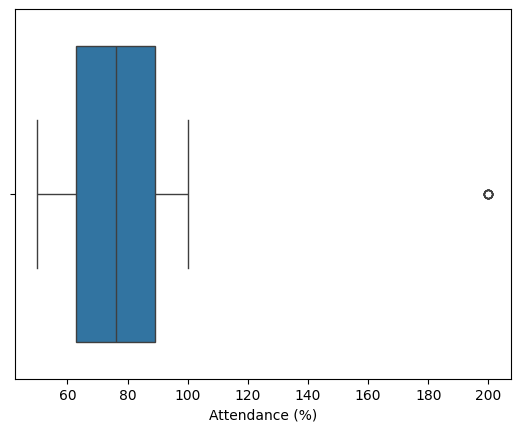

In [ ]:
sns.boxplot(x=train_data['Attendance (%)'])
plt.show()

In [ ]:
# Inspect negative Study Hours before correcting them
for index, row in train_data.iterrows():
    if row["Study Hours"] < 0:
        print(row)

# Convert impossible values to NaN BEFORE calculating medians.
for df in (train_data, validation_data, test_data):
    df.loc[(df['Attendance (%)'] < 0) | (df['Attendance (%)'] > 100), 'Attendance (%)'] = np.nan
    df.loc[df['Study Hours'] < 0, 'Study Hours'] = np.nan

# Detect statistical outliers in training data using the IQR rule.
# Report them; do not automatically delete plausible observations.
for col in ['PreviousGrade', 'ExtracurricularActivities', 'Study Hours', 'Attendance (%)']:
    q1 = train_data[col].quantile(0.25)
    q3 = train_data[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    count = ((train_data[col] < lower) | (train_data[col] > upper)).sum()
    print(f"{col}: {count} IQR outliers")

Gender                       Female
PreviousGrade                  82.0
ExtracurricularActivities       2.0
ParentalSupport                 NaN
FinalGrade                     68.0
Study Hours                    -5.0
Attendance (%)                200.0
Online Classes Taken           True
Name: 321, dtype: object
Gender                        Male
PreviousGrade                 85.0
ExtracurricularActivities      2.0
ParentalSupport                Low
FinalGrade                    78.0
Study Hours                   -5.0
Attendance (%)               200.0
Online Classes Taken          True
Name: 380, dtype: object
Gender                       Female
PreviousGrade                   NaN
ExtracurricularActivities       2.0
ParentalSupport                High
FinalGrade                     85.0
Study Hours                    -5.0
Attendance (%)                200.0
Online Classes Taken          False
Name: 251, dtype: object
Gender                        Male
PreviousGrade                 86.0

In [ ]:
most_frequent_extactivities = train_data['ExtracurricularActivities'].mode()[0]
train_data['ExtracurricularActivities'] = train_data['ExtracurricularActivities'].fillna(most_frequent_extactivities)
validation_data['ExtracurricularActivities'] = validation_data['ExtracurricularActivities'].fillna(most_frequent_extactivities)
test_data['ExtracurricularActivities'] = test_data['ExtracurricularActivities'].fillna(most_frequent_extactivities)

In [ ]:
most_frequent_classes = train_data['Online Classes Taken'].mode()[0]
train_data['Online Classes Taken'] = train_data['Online Classes Taken'].fillna(most_frequent_classes)
validation_data['Online Classes Taken'] = validation_data['Online Classes Taken'].fillna(most_frequent_classes)
test_data['Online Classes Taken'] = test_data['Online Classes Taken'].fillna(most_frequent_classes)

/tmp/ipykernel_5180/1179248996.py:2: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  train_data['Online Classes Taken'] = train_data['Online Classes Taken'].fillna(most_frequent_classes)
/tmp/ipykernel_5180/1179248996.py:3: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  validation_data['Online Classes Taken'] = validation_data['Online Classes Taken'].fillna(most_frequent_classes)
/tmp/ipykernel_5180/1179248996.py:4: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_

In [ ]:
most_frequent_support = train_data['ParentalSupport'].mode()[0]
train_data['ParentalSupport'] = train_data['ParentalSupport'].fillna(most_frequent_support)
validation_data['ParentalSupport'] = validation_data['ParentalSupport'].fillna(most_frequent_support)
test_data['ParentalSupport'] = test_data['ParentalSupport'].fillna(most_frequent_support)

In [ ]:
most_frequent_gender = train_data['Gender'].mode()[0]
train_data['Gender'] = train_data['Gender'].fillna(most_frequent_gender)
validation_data['Gender'] = validation_data['Gender'].fillna(most_frequent_gender)
test_data['Gender'] = test_data['Gender'].fillna(most_frequent_gender)

In [ ]:
median_27 = train_data['PreviousGrade'].median()
train_data['PreviousGrade'] = train_data['PreviousGrade'].fillna(median_27)
validation_data['PreviousGrade'] = validation_data['PreviousGrade'].fillna(median_27)
test_data['PreviousGrade'] = test_data['PreviousGrade'].fillna(median_27)

In [ ]:
median_28 = train_data['Study Hours'].median()
train_data['Study Hours'] = train_data['Study Hours'].fillna(median_28)
validation_data['Study Hours'] = validation_data['Study Hours'].fillna(median_28)
test_data['Study Hours'] = test_data['Study Hours'].fillna(median_28)

In [ ]:
median_29 = train_data['Attendance (%)'].median()
train_data['Attendance (%)'] = train_data['Attendance (%)'].fillna(median_29)
validation_data['Attendance (%)'] = validation_data['Attendance (%)'].fillna(median_29)
test_data['Attendance (%)'] = test_data['Attendance (%)'].fillna(median_29)

In [ ]:
print("Missing values:")
print("Train:", train_data.isnull().sum().sum())
print("Validation:", validation_data.isnull().sum().sum())
print("Test:", test_data.isnull().sum().sum())

for name, df in [('Train', train_data), ('Validation', validation_data), ('Test', test_data)]:
    print(f"\\n{name} ranges:")
    print(df[['Attendance (%)', 'Study Hours']].describe().loc[['min', 'max']])

Missing values:
Train: 0
Validation: 0
Test: 0
\nTrain ranges:
     Attendance (%)  Study Hours
min            50.0          0.0
max           100.0          5.0
\nValidation ranges:
     Attendance (%)  Study Hours
min            50.0          0.0
max           100.0          5.0
\nTest ranges:
     Attendance (%)  Study Hours
min            50.0          0.1
max           100.0          5.0


In [ ]:
# Confirm that the three datasets contain the same columns in the same order.
assert list(train_data.columns) == list(validation_data.columns)
assert list(train_data.columns) == list(test_data.columns)
print("Train, validation, and test columns match.")

Train, validation, and test columns match.


In [ ]:
# Final check: impossible values should have been corrected before imputation.
for name, df in [('Train', train_data), ('Validation', validation_data), ('Test', test_data)]:
    assert df['Attendance (%)'].between(0, 100).all()
    assert (df['Study Hours'] >= 0).all()
    print(name, "minimum/maximum:")
    print(df[['Attendance (%)', 'Study Hours']].agg(['min', 'max']))

Train minimum/maximum:
     Attendance (%)  Study Hours
min            50.0          0.0
max           100.0          5.0
Validation minimum/maximum:
     Attendance (%)  Study Hours
min            50.0          0.0
max           100.0          5.0
Test minimum/maximum:
     Attendance (%)  Study Hours
min            50.0          0.1
max           100.0          5.0


In [ ]:
for d in (train_data, validation_data, test_data):
    d['Online Classes Taken'] = d['Online Classes Taken'].map({True: 1, False: 0})
    d['ParentalSupport'] = d['ParentalSupport'].map({'Low': 0, 'Medium': 1, 'High': 2})
    d['Gender'] = d['Gender'].map({'Male': 0, 'Female': 1})
    assert not d[['Online Classes Taken', 'ParentalSupport', 'Gender']].isnull().any().any()

print(train_data.dtypes)

Gender                         int64
PreviousGrade                float64
ExtracurricularActivities    float64
ParentalSupport                int64
FinalGrade                   float64
Study Hours                  float64
Attendance (%)               float64
Online Classes Taken           int64
dtype: object


In [ ]:
# Standardize numerical and ordinal columns using training statistics only.
cols = ['PreviousGrade', 'ExtracurricularActivities',
        'Study Hours', 'Attendance (%)', 'ParentalSupport']

std_scaler = StandardScaler()
std_scaler.fit(train_data[cols])

train_scaled = std_scaler.transform(train_data[cols])
validation_scaled = std_scaler.transform(validation_data[cols])
test_scaled = std_scaler.transform(test_data[cols])

print(train_scaled.mean(axis=0).round(2))
print(train_scaled.std(axis=0).round(2))
print(validation_scaled.mean(axis=0).round(2))
print(test_scaled.mean(axis=0).round(2))

[ 0. -0. -0. -0. -0.]
[1. 1. 1. 1. 1.]
[-0.05  0.   -0.01  0.08 -0.1 ]
[-0.09  0.02  0.   -0.04 -0.05]


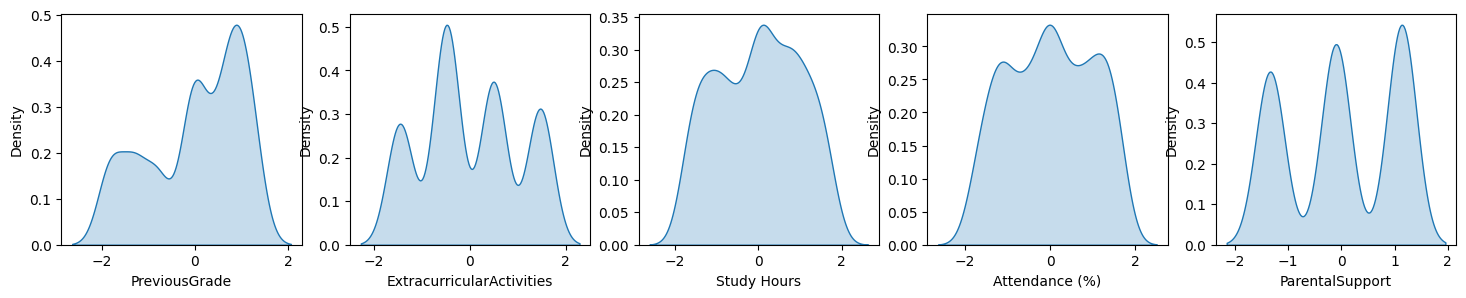

In [ ]:
#plot the standardized values of every column
fig, axes = plt.subplots(1, 5, figsize=(18, 3))

for i, col in enumerate(cols):
    sns.kdeplot(train_scaled[:, i], fill=True, ax=axes[i])
    axes[i].set_xlabel(col)

plt.show()

In [ ]:
#create a new column: 1 if the attendance is 75% or more, otherwise 0
train_data['HighAttendance'] = (train_data['Attendance (%)'] >= 75).astype(int)

#average final grade of each group
print(train_data.groupby('HighAttendance')['FinalGrade'].mean().round(2))

HighAttendance
0    80.02
1    79.93
Name: FinalGrade, dtype: float64


In [ ]:
train_data = train_data.drop(columns=['HighAttendance'])

In [ ]:
train_data.to_csv("train_clean.csv", index=False)
validation_data.to_csv("validation_clean.csv", index=False)
test_data.to_csv("test_clean.csv", index=False)

In [ ]:
#Regression Model

1. Prepare the data

In [ ]:
target = "FinalGrade"

X_train = train_data.drop(columns=target)
y_train = train_data[target]

X_validation = validation_data.drop(columns=target)
y_validation = validation_data[target]

X_test = test_data.drop(columns=target)
y_test = test_data[target]

print("Train:", X_train.shape)
print("Validation:", X_validation.shape)
print("Test:", X_test.shape)
print(list(X_train.columns))

Train: (672, 7)
Validation: (144, 7)
Test: (144, 7)
['Gender', 'PreviousGrade', 'ExtracurricularActivities', 'ParentalSupport', 'Study Hours', 'Attendance (%)', 'Online Classes Taken']


In [ ]:
# Use the scaled numerical columns created in Task 0,
# and keep the already encoded binary columns.
feature_order = ["Gender", "PreviousGrade", "ExtracurricularActivities",
                 "ParentalSupport", "Study Hours", "Attendance (%)",
                 "Online Classes Taken"]

X_train_model = pd.DataFrame(train_scaled, columns=cols, index=train_data.index)
X_validation_model = pd.DataFrame(validation_scaled, columns=cols, index=validation_data.index)
X_test_model = pd.DataFrame(test_scaled, columns=cols, index=test_data.index)

for df_model, df_original in [
    (X_train_model, train_data),
    (X_validation_model, validation_data),
    (X_test_model, test_data)
]:
    df_model["Gender"] = df_original["Gender"].to_numpy()
    df_model["Online Classes Taken"] = df_original["Online Classes Taken"].to_numpy()

X_train_model = X_train_model[feature_order]
X_validation_model = X_validation_model[feature_order]
X_test_model = X_test_model[feature_order]

print(X_train_model.shape, X_validation_model.shape, X_test_model.shape)

(672, 7) (144, 7) (144, 7)


In [ ]:
#baseline
# Calculate the mean of the training target
baseline_value = y_train.mean()

# Predict the same value for all validation students
baseline_validation_predictions = np.full(
    len(y_validation),
    baseline_value
)

# Display the results
print("Baseline prediction:", baseline_value)
print("Number of predictions:", len(baseline_validation_predictions))
print("First 10 predictions:", baseline_validation_predictions[:10])
print("Baseline - Validation")
print("R2:", r2_score(y_validation, baseline_validation))
print("MAE:", mean_absolute_error(y_validation, baseline_validation))
print("RMSE:", np.sqrt(mean_squared_error(y_validation, baseline_validation)))

Baseline prediction: 79.9702380952381
Number of predictions: 144
First 10 predictions: [79.9702381 79.9702381 79.9702381 79.9702381 79.9702381 79.9702381
 79.9702381 79.9702381 79.9702381 79.9702381]
Baseline - Validation
R2: -0.0005165850557924401
MAE: 8.081349206349206
RMSE: 9.561473145257638


In [ ]:
# LINEAR REGRESSION

In [ ]:
X = X_train_model.copy()
y = y_train.copy()

X["intercept"] = 1
X = X[["intercept", "Gender", "PreviousGrade", "ExtracurricularActivities",
       "ParentalSupport", "Study Hours", "Attendance (%)", "Online Classes Taken"]]

In [ ]:
X

,intercept,Gender,PreviousGrade,ExtracurricularActivities,ParentalSupport,Study Hours,Attendance (%),Online Classes Taken
243,1,1,1.041833,-1.452723,-0.097378,-0.923995,1.267861,1
336,1,1,-1.312345,-0.478442,1.137301,-0.707645,-0.414276,0
747,1,1,-0.084078,-1.452723,1.137301,-0.779762,-0.974989,0
227,1,1,0.018278,1.470121,-1.332057,-0.923995,-1.185256,1
83,1,1,0.427700,1.470121,-0.097378,0.229872,-1.605790,1
...,...,...,...,...,...,...,...,...
111,1,1,-1.312345,1.470121,1.137301,1.383739,-0.204009,0
286,1,0,1.041833,-0.478442,1.137301,0.446222,0.216525,1
896,1,1,0.427700,-1.452723,1.137301,-1.212462,1.337950,1
455,1,1,-0.800567,0.495840,-1.332057,-0.851879,0.146436,0


In [ ]:
X_T=X.T

In [ ]:
# Calculate the coefficients using the Normal Equation.
# pinv is more stable than inv if the matrix is singular or nearly singular.
B = np.linalg.pinv(X.to_numpy().T @ X.to_numpy()) @ X.to_numpy().T @ y.to_numpy()
B = pd.Series(B, index=X.columns)
B

,0
intercept,79.675565
Gender,0.110327
PreviousGrade,0.176658
ExtracurricularActivities,-0.845333
ParentalSupport,-0.305701
Study Hours,0.288495
Attendance (%),0.232597
Online Classes Taken,0.477506


In [ ]:
# Predict on the training and validation sets
X_validation_with_intercept = X_validation_model.copy()
X_validation_with_intercept["intercept"] = 1
X_validation_with_intercept = X_validation_with_intercept[X.columns]

predictions = X.to_numpy() @ B.to_numpy()
validation_predictions_lr = X_validation_with_intercept.to_numpy() @ B.to_numpy()

from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

print("Linear Regression - Train")
print("R2:", r2_score(y_train, predictions))
print("MAE:", mean_absolute_error(y_train, predictions))
print("RMSE:", np.sqrt(mean_squared_error(y_train, predictions)))

print("\\nLinear Regression - Validation")
print("R2:", r2_score(y_validation, validation_predictions_lr))
print("MAE:", mean_absolute_error(y_validation, validation_predictions_lr))
print("RMSE:", np.sqrt(mean_squared_error(y_validation, validation_predictions_lr)))

Linear Regression - Train
R2: 0.011122138243250701
MAE: 8.16242530303687
RMSE: 9.530565356130433
\nLinear Regression - Validation
R2: -0.02540859240808313
MAE: 8.103667658699123
RMSE: 9.679683108215677


In [ ]:
SSR = ((y - predictions) ** 2).sum()

In [ ]:
SST=((y - y.mean()) ** 2).sum()

In [ ]:
SSR

np.float64(61038.886277022255)

In [ ]:
SST

np.float64(61725.40476190476)

In [ ]:
R2= 1- (SSR/SST)

In [ ]:
R2

np.float64(0.011122138243250701)

In [ ]:
MAE = np.abs(y - predictions).mean()

In [ ]:
MAE

np.float64(8.16242530303687)

In [ ]:
RMSE = np.sqrt(((y - predictions) ** 2).mean())

In [ ]:
base = np.full(len(y), y_train.mean())
print(np.abs(y - base).mean(), np.sqrt(((y - base) ** 2).mean()))

8.171715561224488 9.584011732864877


In [ ]:
#2  RANDOM FORSET REGRESSION

In [ ]:
from sklearn.ensemble import RandomForestRegressor

rf = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

rf.fit(X_train_model, y_train)
predictions_rf = rf.predict(X_validation_model)

print("Random Forest - Validation")
print("R2:", r2_score(y_validation, predictions_rf))
print("MAE:", mean_absolute_error(y_validation, predictions_rf))
print("RMSE:", np.sqrt(mean_squared_error(y_validation, predictions_rf)))

Random Forest - Validation
R2: 0.025169605798781247
MAE: 7.986805555555555
RMSE: 9.437939614485074


In [ ]:
#4. Baseline model

In [ ]:
#5. Ridge Regression

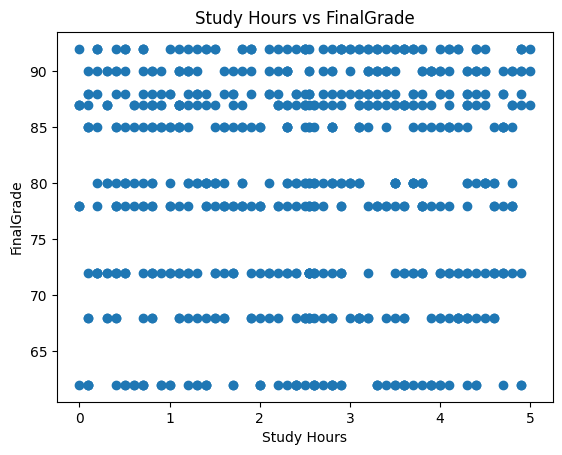

In [ ]:
plt.scatter(
    train_data['Study Hours'],
    train_data['FinalGrade']
)

plt.xlabel('Study Hours')
plt.ylabel('FinalGrade')
plt.title('Study Hours vs FinalGrade')

plt.show()

In [ ]:
# Standardized inputs are used here as well.
X1 = X_train_model.copy()
y1 = y_train.copy()

X1["intercept"] = 1
X1 = X1[["intercept", "Gender", "PreviousGrade", "ExtracurricularActivities",
         "ParentalSupport", "Study Hours", "Attendance (%)", "Online Classes Taken"]]

X1_validation = X_validation_model.copy()
X1_validation["intercept"] = 1
X1_validation = X1_validation[X1.columns]

In [ ]:
# Try the alpha values and choose the one with the lowest validation MAE.
alphas = [10**i for i in range(-2, 4)]
error = []

for alpha in alphas:
    I = np.identity(X1.shape[1])
    I[0, 0] = 0  # Do not penalize the intercept
    penalty = alpha * I

    B1_try = np.linalg.pinv(X1.to_numpy().T @ X1.to_numpy() + penalty) @ X1.to_numpy().T @ y1.to_numpy()
    validation_pred_try = X1_validation.to_numpy() @ B1_try
    error.append(mean_absolute_error(y_validation, validation_pred_try))

results_alpha = pd.DataFrame({"alpha": alphas, "validation_MAE": error})
display(results_alpha)

best_alpha = alphas[int(np.argmin(error))]
print("Best alpha:", best_alpha)

,alpha,validation_MAE
0,0.01,8.103667
1,0.10,8.103659
2,1.00,8.103581
3,10.00,8.102888
4,100.00,8.098432
5,1000.00,8.091429


Best alpha: 1000


In [ ]:
# Fit the manual Ridge model using the selected alpha
I = np.identity(X1.shape[1])
I[0, 0] = 0
penalty = best_alpha * I

B1 = np.linalg.pinv(X1.to_numpy().T @ X1.to_numpy() + penalty) @ X1.to_numpy().T @ y1.to_numpy()
B1 = pd.Series(B1, index=X1.columns)

ridge_validation_predictions = X1_validation.to_numpy() @ B1.to_numpy()

print("Ridge Regression - Validation")
print("R2:", r2_score(y_validation, ridge_validation_predictions))
print("MAE:", mean_absolute_error(y_validation, ridge_validation_predictions))
print("RMSE:", np.sqrt(mean_squared_error(y_validation, ridge_validation_predictions)))

Ridge Regression - Validation
R2: -0.007419198051808129
MAE: 8.091428910198529
RMSE: 9.594398989726669


In [ ]:
#6. Compare models on the validation set

In [ ]:
validation_results = pd.DataFrame({
    "Model": ["Baseline", "Linear Regression", "Random Forest", "Ridge Regression"],
    "R2": [
        r2_score(y_validation, baseline_validation),
        r2_score(y_validation, validation_predictions_lr),
        r2_score(y_validation, predictions_rf),
        r2_score(y_validation, ridge_validation_predictions)
    ],
    "MAE": [
        mean_absolute_error(y_validation, baseline_validation),
        mean_absolute_error(y_validation, validation_predictions_lr),
        mean_absolute_error(y_validation, predictions_rf),
        mean_absolute_error(y_validation, ridge_validation_predictions)
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(y_validation, baseline_validation)),
        np.sqrt(mean_squared_error(y_validation, validation_predictions_lr)),
        np.sqrt(mean_squared_error(y_validation, predictions_rf)),
        np.sqrt(mean_squared_error(y_validation, ridge_validation_predictions))
    ]
})
display(validation_results.sort_values("MAE"))

,Model,R2,MAE,RMSE
2,Random Forest,0.025170,7.986806,9.437940
0,Baseline,-0.000517,8.081349,9.561473
3,Ridge Regression,-0.007419,8.091429,9.594399
1,Linear Regression,-0.025409,8.103668,9.679683


In [ ]:
#7. Final evaluation on the test set

In [ ]:
# Final predictions on the test set
X_test_with_intercept = X_test_model.copy()
X_test_with_intercept["intercept"] = 1
X_test_with_intercept = X_test_with_intercept[X.columns]

lr_test_predictions = X_test_with_intercept.to_numpy() @ B.to_numpy()
rf_test_predictions = rf.predict(X_test_model)

X1_test = X_test_model.copy()
X1_test["intercept"] = 1
X1_test = X1_test[X1.columns]
ridge_test_predictions = X1_test.to_numpy() @ B1.to_numpy()

baseline_test = np.full(len(y_test), y_train.mean())

test_results = pd.DataFrame({
    "Model": ["Baseline", "Linear Regression", "Random Forest", "Ridge Regression"],
    "R2": [
        r2_score(y_test, baseline_test),
        r2_score(y_test, lr_test_predictions),
        r2_score(y_test, rf_test_predictions),
        r2_score(y_test, ridge_test_predictions)
    ],
    "MAE": [
        mean_absolute_error(y_test, baseline_test),
        mean_absolute_error(y_test, lr_test_predictions),
        mean_absolute_error(y_test, rf_test_predictions),
        mean_absolute_error(y_test, ridge_test_predictions)
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(y_test, baseline_test)),
        np.sqrt(mean_squared_error(y_test, lr_test_predictions)),
        np.sqrt(mean_squared_error(y_test, rf_test_predictions)),
        np.sqrt(mean_squared_error(y_test, ridge_test_predictions))
    ]
})
display(test_results.sort_values("MAE"))

,Model,R2,MAE,RMSE
0,Baseline,-0.000416,7.547454,8.954917
3,Ridge Regression,-0.002941,7.574428,8.966211
1,Linear Regression,-0.017967,7.623958,9.033127
2,Random Forest,-0.097889,7.721181,9.381030


In [ ]:
#8. Data visualization

In [ ]:
print(train_data.describe().T)

                           count       mean        std   min   25%    50%  \
Gender                     672.0   0.436012   0.496258   0.0   0.0   0.00   
PreviousGrade              672.0  77.821429   9.777142  60.0  70.0  78.00   
ExtracurricularActivities  672.0   1.491071   1.027162   0.0   1.0   1.00   
ParentalSupport            672.0   1.078869   0.810530   0.0   0.0   1.00   
FinalGrade                 672.0  79.970238   9.591151  62.0  72.0  80.00   
Study Hours                672.0   2.481250   1.387674   0.0   1.3   2.55   
Attendance (%)             672.0  75.910714  14.278194  50.0  64.0  76.00   
Online Classes Taken       672.0   0.516369   0.500104   0.0   0.0   1.00   

                            75%    max  
Gender                      1.0    1.0  
PreviousGrade              86.0   90.0  
ExtracurricularActivities   2.0    3.0  
ParentalSupport             2.0    2.0  
FinalGrade                 88.0   92.0  
Study Hours                 3.6    5.0  
Attendance (%)     

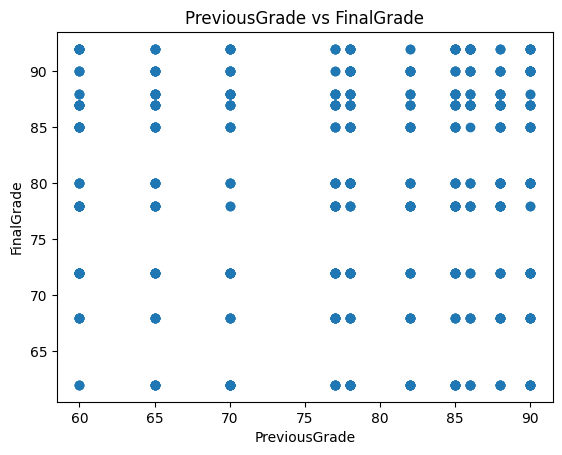

In [ ]:
plt.scatter(train_data["PreviousGrade"], train_data["FinalGrade"])
plt.xlabel("PreviousGrade")
plt.ylabel("FinalGrade")
plt.title("PreviousGrade vs FinalGrade")
plt.show()

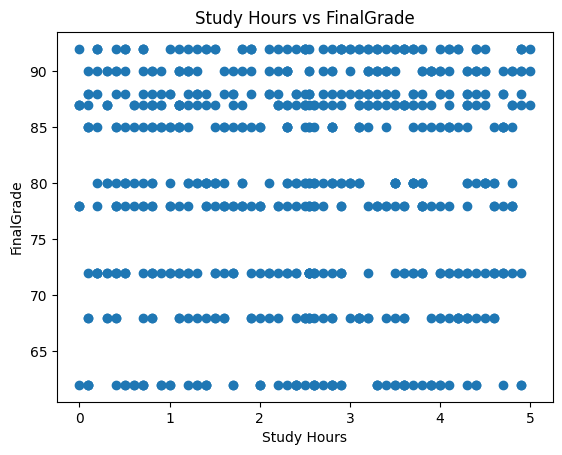

In [ ]:
plt.scatter(train_data["Study Hours"], train_data["FinalGrade"])
plt.xlabel("Study Hours")
plt.ylabel("FinalGrade")
plt.title("Study Hours vs FinalGrade")
plt.show()

In [ ]:
# Random Forest feature importance
feature_importance = pd.Series(rf.feature_importances_, index=X_train_model.columns)
display(feature_importance.sort_values(ascending=False))

,0
Attendance (%),0.288941
Study Hours,0.285489
PreviousGrade,0.174370
ExtracurricularActivities,0.093023
ParentalSupport,0.073914
Gender,0.042260
Online Classes Taken,0.042003


In [ ]:
# TASK2 CLUSTERING

In [ ]:
features = ["Study Hours","Attendance (%)","PreviousGrade"]
cluster_data = train_data[features]
cluster_data.head()


,Study Hours,Attendance (%),PreviousGrade
243,1.2,94.0,88.0
336,1.5,70.0,65.0
747,1.4,62.0,77.0
227,1.2,59.0,78.0
83,2.8,53.0,82.0


In [ ]:
cluster_data.shape

(672, 3)

In [ ]:
cluster_data.head()
cluster_data.describe()

,Study Hours,Attendance (%),PreviousGrade
count,672.000000,672.000000,672.000000
mean,2.481250,75.910714,77.821429
std,1.387674,14.278194,9.777142
min,0.000000,50.000000,60.000000
25%,1.300000,64.000000,70.000000
50%,2.550000,76.000000,78.000000
75%,3.600000,88.000000,86.000000
max,5.000000,100.000000,90.000000


In [ ]:
def standardization(data):
    mean = data.mean()
    std = data.std()

    scaled_data = (data - mean) / std

    return scaled_data

In [ ]:
scaled_data = standardization(cluster_data)

In [ ]:
print(scaled_data.head())

print(scaled_data.mean())
print(scaled_data.std())

     Study Hours  Attendance (%)  PreviousGrade
243    -0.923308        1.266917       1.041058
336    -0.707119       -0.413968      -1.311368
747    -0.779182       -0.974263      -0.084015
227    -0.923308       -1.184373       0.018264
83      0.229701       -1.604595       0.427382
Study Hours      -1.255609e-16
Attendance (%)   -4.229421e-16
PreviousGrade     2.194012e-16
dtype: float64
Study Hours       1.0
Attendance (%)    1.0
PreviousGrade     1.0
dtype: float64


In [ ]:
import math

def euclidean_distance(point, centroid):
    distance = 0

    for i in range(len(point)):
        distance += (point[i] - centroid[i]) ** 2

    distance = math.sqrt(distance)

    return distance

In [ ]:
def initialize_centroids(data, k):
    random_indices = np.random.choice(data.shape[0], k, replace=False)

    centroids = data.iloc[random_indices].values

    return centroids

In [ ]:
k = 3

centroids = initialize_centroids(scaled_data, k)

print(centroids)
print(centroids.shape)

[[-0.85124464  0.77665884  1.24561671]
 [ 0.30176397  1.33695378 -0.79997085]
 [ 0.30176397  0.70662197  0.8364992 ]]
(3, 3)


In [ ]:
def assign_clusters(data, centroids):
    labels = []

    for i in range(len(data)):
        distances = []

        for j in range(len(centroids)):
            distance = euclidean_distance(data[i], centroids[j])
            distances.append(distance)

        cluster = distances.index(min(distances))
        labels.append(cluster)

    return labels

In [ ]:

def update_centroids(data, labels, k, old_centroids):
    new_centroids = []

    for cluster in range(k):
        cluster_points = []

        for i in range(len(data)):
            if labels[i] == cluster:
                cluster_points.append(data[i])

        if len(cluster_points) > 0:
            centroid = []

            for feature in range(data.shape[1]):
                total = 0

                for point in cluster_points:
                    total += point[feature]

                mean = total / len(cluster_points)
                centroid.append(mean)

            new_centroids.append(centroid)

        else:
            new_centroids.append(old_centroids[cluster])

    return np.array(new_centroids)


In [ ]:
k = 3

centroids = initialize_centroids(scaled_data, k)

labels = assign_clusters(scaled_data.values, centroids)

print(labels[:10])
print("Number of students:", len(labels))

[2, 0, 0, 0, 0, 0, 0, 0, 1, 0]
Number of students: 672


In [ ]:
new_centroids = update_centroids(
    scaled_data.values,
    labels,
    k,
    centroids
)

print(new_centroids)
print(new_centroids.shape)

[[ 0.17514854 -0.20549369  0.36142582]
 [ 0.51677172 -0.24863498 -1.52095662]
 [-1.13122726  0.96954726  0.25300373]]
(3, 3)


In [ ]:

def centroids_converged(old_centroids, new_centroids, tolerance=0.0001):

    for i in range(len(old_centroids)):
        distance = euclidean_distance(old_centroids[i], new_centroids[i])

        if distance > tolerance:
            return False

    return True


In [ ]:

def kmeans(data, k, max_iters=100):

    centroids = initialize_centroids(
        pd.DataFrame(data), k
    )

    for iteration in range(max_iters):

        labels = assign_clusters(data, centroids)

        new_centroids = update_centroids(
            data, labels, k, centroids
        )

        if centroids_converged(centroids, new_centroids):
            centroids = new_centroids
            print("Converged at iteration:", iteration + 1)
            break

        centroids = new_centroids

    labels = assign_clusters(data, centroids)

    return labels, centroids


In [ ]:
labels = assign_clusters(scaled_data.values, centroids)

In [ ]:
cluster_results = cluster_data.copy()

cluster_results["Cluster"] = labels
cluster_results["FinalGrade"] = train_data["FinalGrade"]

print(cluster_results.head())

     Study Hours  Attendance (%)  PreviousGrade  Cluster  FinalGrade
243          1.2            94.0           88.0        2        88.0
336          1.5            70.0           65.0        0        80.0
747          1.4            62.0           77.0        0        68.0
227          1.2            59.0           78.0        0        90.0
83           2.8            53.0           82.0        0        85.0


In [ ]:
print(cluster_results["Cluster"].value_counts().sort_index())

Cluster
0    428
1    122
2    122
Name: count, dtype: int64


In [ ]:
cluster_summary = cluster_results.groupby("Cluster").mean()

print(cluster_summary)

         Study Hours  Attendance (%)  PreviousGrade  FinalGrade
Cluster                                                        
0           2.724299       72.976636      81.355140   80.112150
1           3.198361       72.360656      62.950820   80.303279
2           0.911475       89.754098      80.295082   79.139344


In [ ]:
def calculate_wcss(data, labels, centroids):
    wcss = 0

    for i in range(len(data)):
        cluster = labels[i]
        distance = euclidean_distance(data[i], centroids[cluster])
        wcss += distance ** 2

    return wcss

In [ ]:
wcss = calculate_wcss(
    scaled_data.values,
    labels,
    centroids
)

print("WCSS:", wcss)

WCSS: 1618.3027013226508


In [ ]:
k_values = range(1, 11)
wcss_values = []

for k in k_values:

    centroids = initialize_centroids(scaled_data, k)

    labels, centroids = kmeans(scaled_data.values, k)

    wcss = calculate_wcss(
        scaled_data.values,
        labels,
        centroids
    )

    wcss_values.append(wcss)

    print("K =", k, "WCSS =", wcss)

Converged at iteration: 2
K = 1 WCSS = 2012.9999999999973
Converged at iteration: 12
K = 2 WCSS = 1520.2733465279762
Converged at iteration: 9
K = 3 WCSS = 1106.82027440649
Converged at iteration: 16
K = 4 WCSS = 985.5924771861435
Converged at iteration: 13
K = 5 WCSS = 754.3470363732004
Converged at iteration: 15
K = 6 WCSS = 628.8319920527906
Converged at iteration: 19
K = 7 WCSS = 542.5910734526118
Converged at iteration: 20
K = 8 WCSS = 537.7978871483231
Converged at iteration: 23
K = 9 WCSS = 454.4959462136054
Converged at iteration: 37
K = 10 WCSS = 423.4442077753611


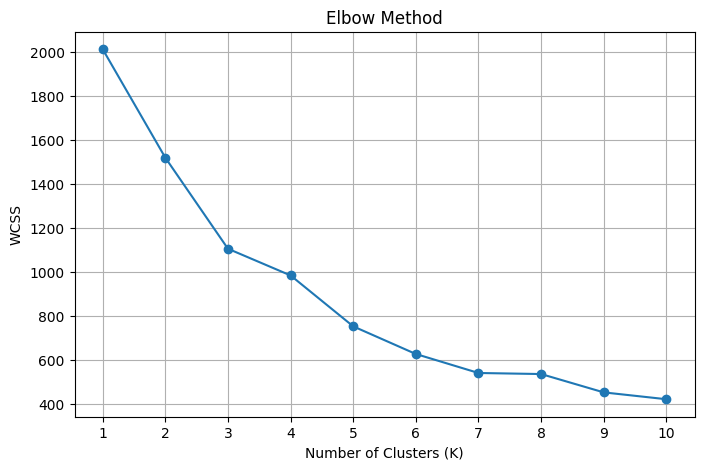

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(list(k_values), wcss_values, marker='o')

plt.xlabel("Number of Clusters (K)")
plt.ylabel("WCSS")
plt.title("Elbow Method")

plt.xticks(list(k_values))
plt.grid(True)

plt.show()

In [ ]:

def calculate_silhouette(data, labels):

    silhouette_values = []
    clusters = sorted(set(labels))

    for i in range(len(data)):

        current_cluster = labels[i]

        # Calculate a(i)
        same_cluster_distances = []

        for j in range(len(data)):
            if labels[j] == current_cluster and i != j:
                distance = euclidean_distance(data[i], data[j])
                same_cluster_distances.append(distance)

        if len(same_cluster_distances) == 0:
            silhouette_values.append(0)
            continue

        a = sum(same_cluster_distances) / len(same_cluster_distances)

        # Calculate b(i)
        other_cluster_means = []

        for cluster in clusters:
            if cluster != current_cluster:

                distances = []

                for j in range(len(data)):
                    if labels[j] == cluster:
                        distance = euclidean_distance(data[i], data[j])
                        distances.append(distance)

                mean_distance = sum(distances) / len(distances)
                other_cluster_means.append(mean_distance)

        b = min(other_cluster_means)

        # Calculate silhouette
        score = (b - a) / max(a, b)

        silhouette_values.append(score)

    return sum(silhouette_values) / len(silhouette_values)


In [ ]:
labels_3, centroids_3 = kmeans(scaled_data.values, 3)
score_3 = calculate_silhouette(scaled_data.values, labels_3)

labels_4, centroids_4 = kmeans(scaled_data.values, 4)
score_4 = calculate_silhouette(scaled_data.values, labels_4)

print("Silhouette Score for K=3:", score_3)
print("Silhouette Score for K=4:", score_4)

Converged at iteration: 9
Converged at iteration: 11
Silhouette Score for K=3: 0.2876580331614277
Silhouette Score for K=4: 0.28018838522790296


In [ ]:
silhouette_values = []

for k in range(2, 11):

    labels, centroids = kmeans(scaled_data.values, k)

    score = calculate_silhouette(
        scaled_data.values,
        labels
    )

    silhouette_values.append(score)

    print("K =", k, "Silhouette =", score)

Converged at iteration: 8
K = 2 Silhouette = 0.2889271465324283
Converged at iteration: 25
K = 3 Silhouette = 0.24289098697995543
Converged at iteration: 22
K = 4 Silhouette = 0.2842102311414576
Converged at iteration: 11
K = 5 Silhouette = 0.3007638127189793
Converged at iteration: 23
K = 6 Silhouette = 0.30394154763750014
Converged at iteration: 20
K = 7 Silhouette = 0.30172785059391977
Converged at iteration: 18
K = 8 Silhouette = 0.2875391504604619
Converged at iteration: 22
K = 9 Silhouette = 0.2895590757630642
Converged at iteration: 20
K = 10 Silhouette = 0.28454938132886826


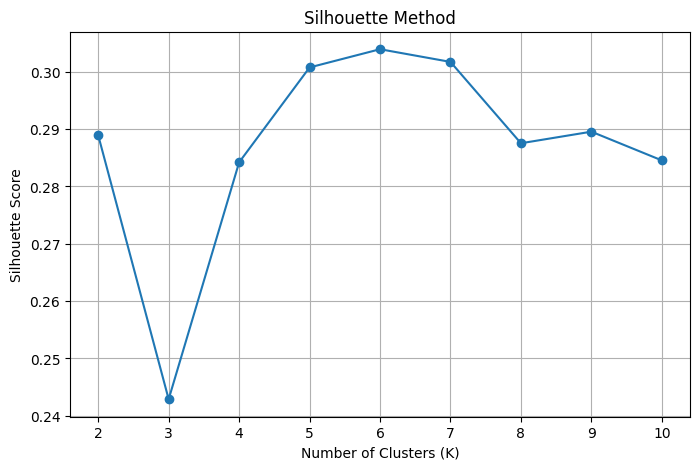

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(range(2, 11), silhouette_values, marker='o')

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Method")

plt.xticks(range(2, 11))
plt.grid(True)

plt.show()

In [ ]:

average_silhouette = []

for k in range(2, 11):

    scores = []

    for run in range(10):

        labels, centroids = kmeans(scaled_data.values, k)

        score = calculate_silhouette(
            scaled_data.values,
            labels
        )

        scores.append(score)

    average_score = sum(scores) / len(scores)

    average_silhouette.append(average_score)

    print("K =", k, "Average Silhouette =", average_score)


Converged at iteration: 20
Converged at iteration: 14
Converged at iteration: 12
Converged at iteration: 5
Converged at iteration: 15
Converged at iteration: 4
Converged at iteration: 24
Converged at iteration: 23
Converged at iteration: 9
Converged at iteration: 26
K = 2 Average Silhouette = 0.26373892429725143
Converged at iteration: 17
Converged at iteration: 29
Converged at iteration: 27
Converged at iteration: 13
Converged at iteration: 52
Converged at iteration: 33
Converged at iteration: 17
Converged at iteration: 11
Converged at iteration: 17
Converged at iteration: 29
K = 3 Average Silhouette = 0.2778009918481314
Converged at iteration: 14
Converged at iteration: 22
Converged at iteration: 15
Converged at iteration: 32
Converged at iteration: 16
Converged at iteration: 8
Converged at iteration: 21
Converged at iteration: 8
Converged at iteration: 10
Converged at iteration: 35
K = 4 Average Silhouette = 0.278366426058901
Converged at iteration: 16
Converged at iteration: 13
Con

In [ ]:
final_k = 5

final_labels, final_centroids = kmeans(
    scaled_data.values,
    final_k
)

Converged at iteration: 32


In [ ]:
final_results = cluster_data.copy()

final_results["Cluster"] = final_labels
final_results["FinalGrade"] = train_data["FinalGrade"]

In [ ]:
print(final_results["Cluster"].value_counts().sort_index())

Cluster
0    104
1    200
2    105
3    133
4    130
Name: count, dtype: int64


In [ ]:
final_summary = final_results.groupby("Cluster").mean()

print(final_summary)

         Study Hours  Attendance (%)  PreviousGrade  FinalGrade
Cluster                                                        
0           3.029327       61.144231      65.625000   79.538462
1           3.639000       80.780000      83.410000   81.060000
2           2.234286       87.142857      64.771429   79.866667
3           1.927444       60.383459      83.030075   79.969925
4           1.027692       87.046154      84.192308   78.723077


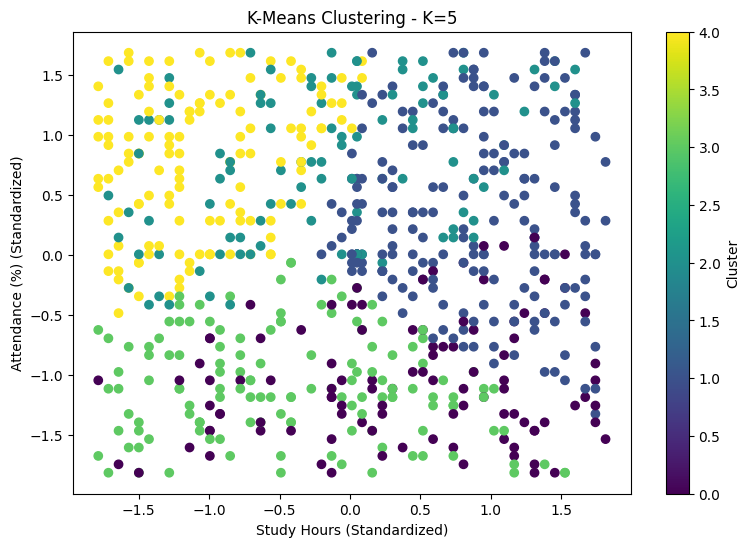

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 6))

plt.scatter(
    scaled_data["Study Hours"],
    scaled_data["Attendance (%)"],
    c=final_labels
)

plt.xlabel("Study Hours (Standardized)")
plt.ylabel("Attendance (%) (Standardized)")
plt.title("K-Means Clustering - K=5")

plt.colorbar(label="Cluster")

plt.show()

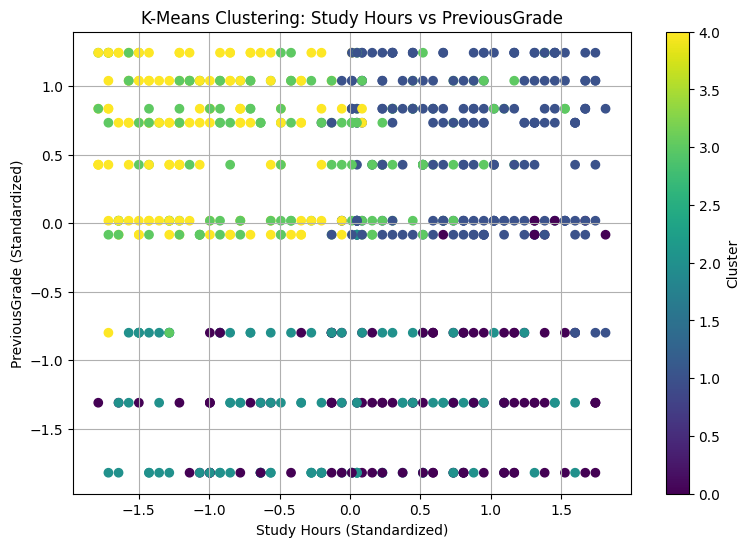

In [ ]:
plt.figure(figsize=(9, 6))

plt.scatter(
    scaled_data["Study Hours"],
    scaled_data["PreviousGrade"],
    c=final_labels
)

plt.xlabel("Study Hours (Standardized)")
plt.ylabel("PreviousGrade (Standardized)")
plt.title("K-Means Clustering: Study Hours vs PreviousGrade")

plt.colorbar(label="Cluster")
plt.grid(True)

plt.show()

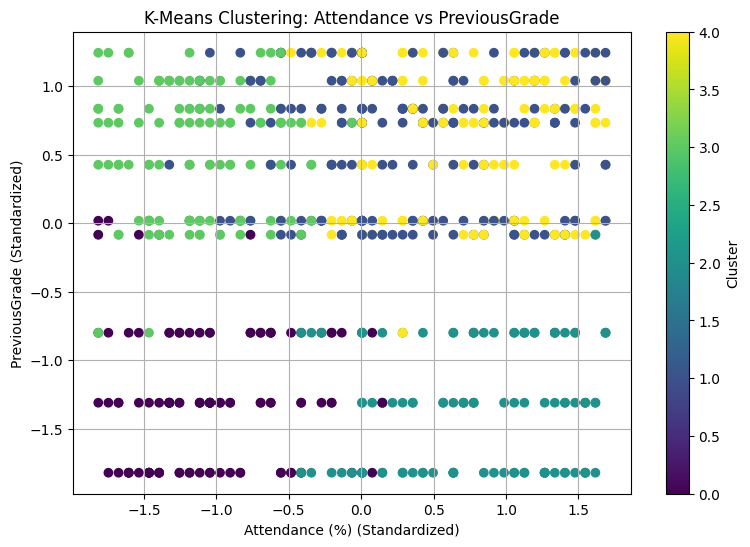

In [ ]:
plt.figure(figsize=(9, 6))

plt.scatter(
    scaled_data["Attendance (%)"],
    scaled_data["PreviousGrade"],
    c=final_labels
)

plt.xlabel("Attendance (%) (Standardized)")
plt.ylabel("PreviousGrade (Standardized)")
plt.title("K-Means Clustering: Attendance vs PreviousGrade")

plt.colorbar(label="Cluster")
plt.grid(True)

plt.show()

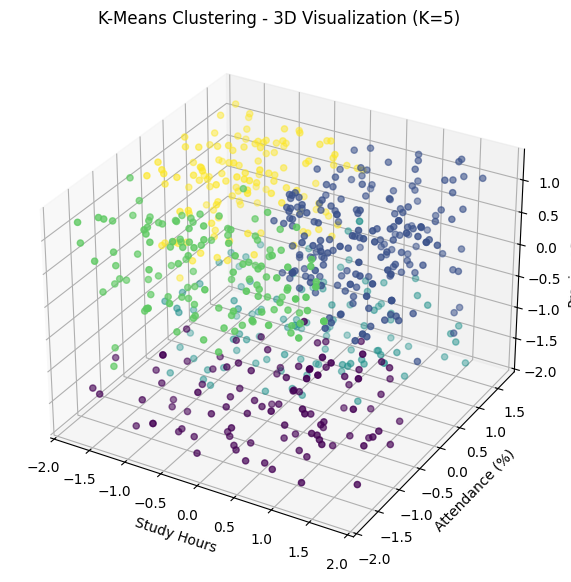

In [ ]:

from mpl_toolkits.mplot3d import Axes3D
import matplotlib.pyplot as plt

fig = plt.figure(figsize=(10, 7))

ax = fig.add_subplot(111, projection='3d')

ax.scatter(
    scaled_data["Study Hours"],
    scaled_data["Attendance (%)"],
    scaled_data["PreviousGrade"],
    c=final_labels
)

ax.set_xlabel("Study Hours")
ax.set_ylabel("Attendance (%)")
ax.set_zlabel("PreviousGrade")

ax.set_title("K-Means Clustering - 3D Visualization (K=5)")

plt.show()


In [ ]:
final_wcss = calculate_wcss(
    scaled_data.values,
    final_labels,
    final_centroids
)

final_silhouette = calculate_silhouette(
    scaled_data.values,
    final_labels
)

print("Final K:", final_k)
print("Final WCSS:", final_wcss)
print("Final Silhouette:", final_silhouette)

Final K: 5
Final WCSS: 747.3984001381577
Final Silhouette: 0.29808795205903194


In [ ]:
print("Cluster distribution:")
print(final_results["Cluster"].value_counts().sort_index())

Cluster distribution:
Cluster
0    104
1    200
2    105
3    133
4    130
Name: count, dtype: int64


In [ ]:

best_wcss = float('inf')
best_labels = None
best_centroids = None

for run in range(10):

    labels, centroids = kmeans(scaled_data.values, 5)

    wcss = calculate_wcss(
        scaled_data.values,
        labels,
        centroids
    )

    if wcss < best_wcss:
        best_wcss = wcss
        best_labels = labels
        best_centroids = centroids

print("Best WCSS:", best_wcss)

best_silhouette = calculate_silhouette(
    scaled_data.values,
    best_labels
)

print("Best Model Silhouette:", best_silhouette)


Converged at iteration: 9
Converged at iteration: 24
Converged at iteration: 16
Converged at iteration: 18
Converged at iteration: 22
Converged at iteration: 33
Converged at iteration: 17
Converged at iteration: 51
Converged at iteration: 14
Converged at iteration: 17
Best WCSS: 741.2517211589325
Best Model Silhouette: 0.3028419076386476


In [ ]:
final_labels = best_labels
final_centroids = best_centroids
final_k = 5

In [ ]:
final_results = cluster_data.copy()

final_results["Cluster"] = final_labels
final_results["FinalGrade"] = train_data["FinalGrade"]

In [ ]:
print(final_results["Cluster"].value_counts().sort_index())

Cluster
0     98
1    131
2    127
3    101
4    215
Name: count, dtype: int64


In [ ]:
final_summary = final_results.groupby("Cluster").mean()

print(final_summary)

         Study Hours  Attendance (%)  PreviousGrade  FinalGrade
Cluster                                                        
0           3.159694       61.357143      65.520408   80.010204
1           1.375191       62.099237      81.503817   80.320611
2           1.222441       89.188976      84.598425   78.921260
3           2.321287       87.485149      64.356436   79.900990
4           3.664651       77.679070      83.506977   80.390698


In [ ]:

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Create K-Means model
sk_model = KMeans(
    n_clusters=5,
    init='random',
    n_init=10,
    max_iter=100,
    random_state=42
)

# Train the model
sk_labels = sk_model.fit_predict(scaled_data)

# Calculate evaluation metrics
sk_wcss = sk_model.inertia_

sk_silhouette = silhouette_score(
    scaled_data,
    sk_labels
)

print("Scikit-learn WCSS:", sk_wcss)
print("Scikit-learn Silhouette:", sk_silhouette)


Scikit-learn WCSS: 745.0200004400499
Scikit-learn Silhouette: 0.29903800866485125


In [ ]:
print(cluster_data.shape)
print(cluster_data.head())
print(cluster_data.columns)

(672, 3)
     Study Hours  Attendance (%)  PreviousGrade
243          1.2            94.0           88.0
336          1.5            70.0           65.0
747          1.4            62.0           77.0
227          1.2            59.0           78.0
83           2.8            53.0           82.0
Index(['Study Hours', 'Attendance (%)', 'PreviousGrade'], dtype='object')


In [ ]:
#2 clusturing

In [ ]:
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score

In [ ]:
hierarchical_model = AgglomerativeClustering(
    n_clusters=5,
    linkage='ward'
)

hierarchical_labels = hierarchical_model.fit_predict(scaled_data)

In [ ]:
print("Cluster labels:")
print(hierarchical_labels)

print("\nNumber of students in each cluster:")
print(pd.Series(hierarchical_labels).value_counts().sort_index())

Cluster labels:
[1 0 3 3 2 3 2 2 0 2 1 0 1 3 1 2 3 3 0 0 2 0 3 4 0 4 0 4 0 1 0 4 1 1 0 3 0
 4 3 4 1 0 2 1 1 2 0 2 1 1 3 1 0 1 0 0 3 0 1 1 2 2 3 1 2 2 4 1 3 1 4 0 3 1
 1 0 1 4 0 2 1 0 1 0 3 1 3 2 0 4 1 2 3 0 0 3 2 1 1 0 1 0 0 3 3 0 1 2 0 0 3
 2 4 2 0 1 3 0 0 2 1 1 0 4 2 1 4 1 0 2 1 0 4 2 2 0 1 4 0 1 1 2 1 1 3 1 0 2
 0 2 1 1 2 2 1 2 3 1 1 3 1 0 0 2 2 2 3 0 1 0 1 4 4 0 0 1 0 0 2 1 1 3 2 4 2
 0 1 1 2 0 1 1 0 1 0 2 3 1 4 1 3 4 4 1 1 0 1 1 1 0 0 2 0 1 1 0 0 1 0 1 2 3
 0 1 2 2 0 3 2 1 1 1 0 1 0 4 1 1 1 0 0 1 3 1 4 2 0 1 0 1 1 4 3 4 1 1 2 0 1
 3 1 0 1 0 2 2 2 0 3 1 1 3 2 2 1 0 2 1 1 4 0 0 0 3 3 1 2 1 1 1 1 3 3 1 0 1
 2 1 3 2 1 2 0 0 0 3 0 3 3 1 2 2 4 0 0 2 3 2 2 0 0 2 0 2 4 0 0 2 0 0 4 0 2
 2 1 3 0 1 0 2 2 0 1 0 0 1 4 1 0 0 0 1 0 3 1 0 0 3 4 4 4 3 1 0 2 2 1 3 3 3
 1 2 0 3 0 1 1 1 2 3 1 1 2 1 0 2 0 4 4 3 0 1 1 1 0 3 0 2 2 3 2 4 0 2 3 3 0
 0 4 3 0 3 2 4 1 0 4 3 1 2 0 0 0 1 1 0 0 2 4 1 3 2 0 0 4 0 1 1 2 3 0 1 2 2
 4 2 1 2 3 0 4 2 2 2 4 2 1 0 2 0 2 0 0 2 1 0 0 1 1 1 2 2 0 2 1 0 1 0 0 1 3
 4 0 1 2 

In [ ]:
hierarchical_silhouette = silhouette_score(
    scaled_data,
    hierarchical_labels
)

print("Hierarchical Silhouette Score:", hierarchical_silhouette)

Hierarchical Silhouette Score: 0.21711401102019695


In [ ]:
hierarchical_results = train_data.copy()

hierarchical_results["Hierarchical_Cluster"] = hierarchical_labels

hierarchical_summary = hierarchical_results.groupby(
    "Hierarchical_Cluster"
)[
    ["Study Hours", "Attendance (%)", "PreviousGrade", "FinalGrade"]
].mean().round(2)

print(hierarchical_summary)

                      Study Hours  Attendance (%)  PreviousGrade  FinalGrade
Hierarchical_Cluster                                                        
0                            2.59           73.90          64.52       79.92
1                            1.85           85.90          83.77       79.59
2                            3.61           64.24          82.73       79.89
3                            0.80           65.65          83.58       79.47
4                            4.08           90.51          82.95       82.17


In [ ]:
print("X_train:", X_train.shape)
print("X_validation:", X_validation.shape)
print("X_test:", X_test.shape)

print("\nFeatures:")
print(X_train.columns.tolist())

print("\nTarget:")
print(y_train.name)

print("\nMissing values:")
print(X_train.isnull().sum())

X_train: (672, 7)
X_validation: (144, 7)
X_test: (144, 7)

Features:
['Gender', 'PreviousGrade', 'ExtracurricularActivities', 'ParentalSupport', 'Study Hours', 'Attendance (%)', 'Online Classes Taken']

Target:
FinalGrade

Missing values:
Gender                       0
PreviousGrade                0
ExtracurricularActivities    0
ParentalSupport              0
Study Hours                  0
Attendance (%)               0
Online Classes Taken         0
dtype: int64
